In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
little_new = pd.read_csv("../EMG Recordings/little_finger 10mins.csv")
middle_new = pd.read_csv("../EMG Recordings/middle_finger_10mins.csv")
ring_new = pd.read_csv("../EMG Recordings/ring_finger_10mins.csv")
index_new = pd.read_csv("../EMG Recordings/index_finger_10mins.csv")
thumb_new = pd.read_csv("../EMG Recordings/thumb_finger_10mins.csv")

print("\nALL DATASETS LOADED")


ALL DATASETS LOADED


In [4]:
recordings = {
    "Little": little_new.head(60745),
    "Middle": middle_new.head(60745),
    "Ring": ring_new.head(60745),
    "Index": index_new.head(60745),
    "Thumb": thumb_new.head(60745)
}

In [5]:
for finger, data in recordings.items():
    print(f"{finger}: {data.shape}")
    assert len(data) == 60745

Little: (60745, 3)
Middle: (60745, 3)
Ring: (60745, 3)
Index: (60745, 3)
Thumb: (60745, 3)


In [6]:
def calculate_statistics(values):

    values = values.astype(float)

    mean_value = np.mean(values)
    median_value = np.median(values)
    minimum_value = np.min(values)
    maximum_value = np.max(values)
    standard_deviation = np.std(values)
    variance_value = np.var(values)
    value_range = maximum_value - minimum_value
    rms_value = np.sqrt(np.mean(values ** 2))
    mean_absolute_value = np.mean(np.abs(values))
    waveform_length = np.sum(np.abs(np.diff(values)))

    return [
        mean_value,
        median_value,
        minimum_value,
        maximum_value,
        standard_deviation,
        variance_value,
        value_range,
        rms_value,
        mean_absolute_value,
        waveform_length
    ]

In [7]:
def create_batches(data, batch_size=10):

    signals = data[["emg1", "emg2"]].values

    batches = []

    for i in range(0, len(signals), batch_size):

        batch = signals[i:i + batch_size]

        if len(batch) == batch_size:

            raw_features = batch.flatten()

            emg1_statistics = calculate_statistics(
                batch[:, 0]
            )

            emg2_statistics = calculate_statistics(
                batch[:, 1]
            )

            combined_features = np.concatenate(
                [
                    raw_features,
                    emg1_statistics,
                    emg2_statistics
                ]
            )

            batches.append(combined_features)

    return np.array(batches)

In [8]:
statistic_names = [
    "Mean",
    "Median",
    "Minimum",
    "Maximum",
    "Standard_Deviation",
    "Variance",
    "Range",
    "RMS",
    "Mean_Absolute_Value",
    "Waveform_Length"
]

feature_names = []

for reading in range(1, 11):

    feature_names.append(
        f"Raw_EMG1_{reading}"
    )

    feature_names.append(
        f"Raw_EMG2_{reading}"
    )

for statistic in statistic_names:

    feature_names.append(
        f"EMG1_{statistic}"
    )

for statistic in statistic_names:

    feature_names.append(
        f"EMG2_{statistic}"
    )

In [9]:
emg_features = []
finger_labels = []

for finger, data in recordings.items():

    batches = create_batches(data)

    for batch in batches:

        emg_features.append(batch)

        finger_labels.append(finger)

emg_features = np.array(emg_features)

finger_labels = np.array(finger_labels)

print("Features:", emg_features.shape)

print("Labels:", finger_labels.shape)

print("Features per batch:", emg_features.shape[1])

print("\nClass distribution:")

print(
    pd.Series(
        finger_labels
    ).value_counts()
)

Features: (30370, 40)
Labels: (30370,)
Features per batch: 40

Class distribution:
Little    6074
Middle    6074
Ring      6074
Index     6074
Thumb     6074
Name: count, dtype: int64


In [10]:
(
    train_features,
    test_features,
    train_labels,
    test_labels

) = train_test_split(

    emg_features,
    finger_labels,

    train_size=0.60,
    test_size=0.40,

    random_state=42,

    stratify=finger_labels
)

print(
    "Training samples:",
    len(train_features)
)

print(
    "Testing samples:",
    len(test_features)
)

Training samples: 18222
Testing samples: 12148


In [11]:
scaler = StandardScaler()

train_features_scaled = scaler.fit_transform(
    train_features
)

test_features_scaled = scaler.transform(
    test_features
)

In [12]:
random_index = np.random.randint(
    0,
    len(test_features)
)

random_raw_features = test_features[
    random_index
]

random_scaled_features = test_features_scaled[
    random_index
]

random_label = test_labels[
    random_index
]

raw_signal = random_raw_features[
    :20
].reshape(
    10,
    2
)

print("\nRandom Test Batch")

print(
    "Finger:",
    random_label
)

print(
    "Batch index:",
    random_index
)

print("\nReading | EMG1 | EMG2")

for i in range(10):

    print(
        f"{i + 1:>7} | "
        f"{raw_signal[i, 0]:>4.0f} | "
        f"{raw_signal[i, 1]:>4.0f}"
    )


Random Test Batch
Finger: Thumb
Batch index: 11002

Reading | EMG1 | EMG2
      1 |   19 |    6
      2 |  102 |    0
      3 |  145 |    0
      4 |  131 |    0
      5 |   32 |    0
      6 |   21 |    3
      7 |   99 |    0
      8 |  159 |    0
      9 |  116 |    6
     10 |   61 |    0


In [13]:
emg1_stats = random_raw_features[
    20:30
]

emg2_stats = random_raw_features[
    30:40
]

print("\nStatistical Features")

print(
    f"{'Statistic':<24}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)

for i in range(
    len(statistic_names)
):

    print(
        f"{statistic_names[i]:<24}"
        f"{emg1_stats[i]:>15.4f}"
        f"{emg2_stats[i]:>15.4f}"
    )


Statistical Features
Statistic                          EMG1           EMG2
Mean                            88.5000         1.5000
Median                         100.5000         0.0000
Minimum                         19.0000         0.0000
Maximum                        159.0000         6.0000
Standard_Deviation              49.3483         2.4187
Variance                      2435.2500         5.8500
Range                          140.0000         6.0000
RMS                            101.3287         2.8460
Mean_Absolute_Value             88.5000         1.5000
Waveform_Length                486.0000        24.0000


In [14]:
scaled_emg1_stats = random_scaled_features[
    20:30
]

scaled_emg2_stats = random_scaled_features[
    30:40
]

print("\nScaled Statistical Features")

print(
    f"{'Statistic':<24}"
    f"{'EMG1':>15}"
    f"{'EMG2':>15}"
)

for i in range(
    len(statistic_names)
):

    print(
        f"{statistic_names[i]:<24}"
        f"{scaled_emg1_stats[i]:>15.4f}"
        f"{scaled_emg2_stats[i]:>15.4f}"
    )


Scaled Statistical Features
Statistic                          EMG1           EMG2
Mean                             1.3379        -0.8121
Median                           1.6202        -0.5145
Minimum                          3.4204        -0.0516
Maximum                          0.6535        -0.9066
Standard_Deviation               0.5916        -0.9236
Variance                         0.2665        -0.3600
Range                            0.4007        -0.9072
RMS                              1.1275        -0.8949
Mean_Absolute_Value              1.3379        -0.8121
Waveform_Length                  0.5961        -0.8603


In [15]:
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

model.fit(
    train_features_scaled,
    train_labels
)

predicted_fingers = model.predict(
    test_features_scaled
)

In [16]:
accuracy = accuracy_score(
    test_labels,
    predicted_fingers
)

correct_predictions = np.sum(
    test_labels == predicted_fingers
)

print(
    "Correct predictions:",
    correct_predictions
)

print(
    "Total test samples:",
    len(test_labels)
)

print(
    f"Accuracy: {accuracy * 100:.4f}%"
)

print(
    "\nClassification Report:\n"
)

print(
    classification_report(
        test_labels,
        predicted_fingers,
        digits=4,
        zero_division=0
    )
)

Correct predictions: 7949
Total test samples: 12148
Accuracy: 65.4346%

Classification Report:

              precision    recall  f1-score   support

       Index     0.5819    0.5144    0.5461      2430
      Little     0.7206    0.8143    0.7646      2429
      Middle     0.5174    0.4893    0.5030      2430
        Ring     0.6443    0.6329    0.6386      2430
       Thumb     0.7759    0.8209    0.7978      2429

    accuracy                         0.6543     12148
   macro avg     0.6480    0.6544    0.6500     12148
weighted avg     0.6480    0.6543    0.6500     12148



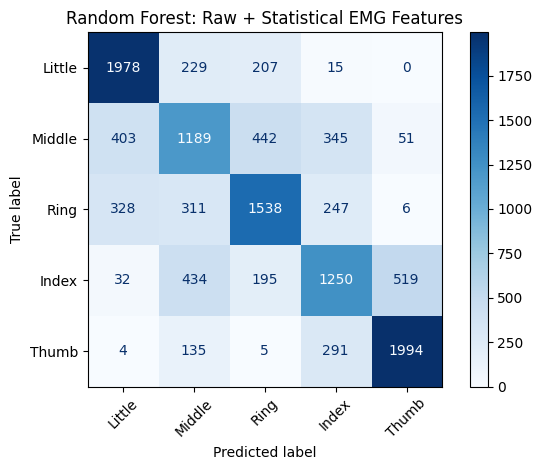

In [17]:
finger_names = [
    "Little",
    "Middle",
    "Ring",
    "Index",
    "Thumb"
]

matrix = confusion_matrix(
    test_labels,
    predicted_fingers,
    labels=finger_names
)

display = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=finger_names
)

display.plot(
    cmap="Blues"
)

plt.title(
    "Random Forest: Raw + Statistical EMG Features"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()

plt.show()

In [18]:
random_prediction = model.predict(
    random_scaled_features.reshape(
        1,
        -1
    )
)

print(
    "Actual:",
    random_label
)

print(
    "Predicted:",
    random_prediction[0]
)

if random_prediction[0] == random_label:

    print("CORRECT")

else:

    print("INCORRECT")

Actual: Thumb
Predicted: Thumb
CORRECT


In [20]:
feature_importance = pd.DataFrame(
    {
        "Feature": feature_names,
        "Importance": model.feature_importances_
    }
)

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

print(
    feature_importance.head(20).to_string(
        index=False
    )
)

                 Feature  Importance
             EMG1_Median    0.082702
               EMG1_Mean    0.081422
EMG1_Mean_Absolute_Value    0.072744
                EMG1_RMS    0.049955
 EMG1_Standard_Deviation    0.042747
           EMG1_Variance    0.040675
    EMG1_Waveform_Length    0.037779
            EMG1_Maximum    0.035258
              EMG1_Range    0.033555
              Raw_EMG1_4    0.024672
                EMG2_RMS    0.023995
              Raw_EMG1_9    0.023939
EMG2_Mean_Absolute_Value    0.023917
             Raw_EMG1_10    0.023618
               EMG2_Mean    0.023600
    EMG2_Waveform_Length    0.022783
 EMG2_Standard_Deviation    0.021548
              Raw_EMG1_8    0.021340
           EMG2_Variance    0.021114
              Raw_EMG1_2    0.021084
